# **Exercice 1**

1. Lire cameraman.tif et l’afficher avec un titre.

cv2.imread('lien image', cv2.IMREAD_GRAYSCALE)

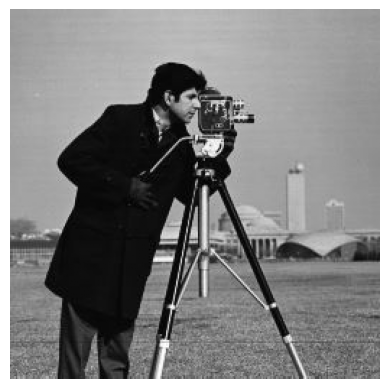

In [ ]:
import matplotlib.pyplot as plt
from skimage import data
import cv2

#image = data.camera()

# Charger l'image cameraman intégrée dans skimage
image = cv2.imread("/content/drive/MyDrive/Traitement d'images/cameraman.jpg", cv2.IMREAD_GRAYSCALE).astype(float)
# Afficher l'image en niveaux de gris
plt.imshow(image, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

2. Déterminer ses dimensions, son nombre de canaux, le type numérique des pixels et les valeurs
minimale et maximale.

In [ ]:
print(image.shape) #dim et rien après donc =1 pour nombre de canaux
print(image.ndim) #dimensions du tableau MAIS PAS nombre de canaux
print(image.dtype) #type numérique des pixels
print(image.min()) #valeur minimale
print(image.max()) #valeur maximale

(256, 256)
2
float64
0.0
255.0


3. Calculer le nombre total de pixels.

In [ ]:
nombre_total_pixel = image.shape[0] * image.shape[1]
print(nombre_total_pixel)

65536


4. Extraire une région de 5 × 5 pixels et afficher ses valeurs numériques.

In [ ]:
# Extraction des 5 premières lignes et 5 premières colonnes
region = image[0:5, 0:5]

# Affichage des valeurs numériques
print("Région 5x5 pixels :")
print(region)

Région 5x5 pixels :
[[157. 157. 157. 157. 157.]
 [157. 157. 157. 157. 157.]
 [158. 158. 158. 158. 158.]
 [157. 157. 157. 157. 157.]
 [156. 156. 156. 156. 156.]]


5. Sur trois copies de l’image, remplacer cette région par 0, 128 puis 255. Afficher les résultats et
observer aussi un agrandissement de la région.

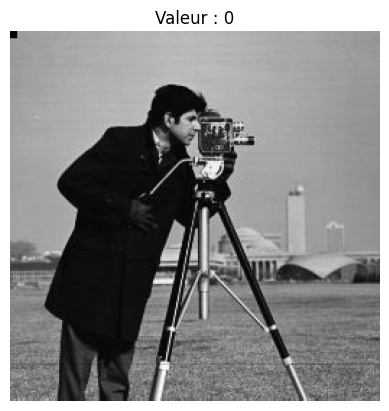

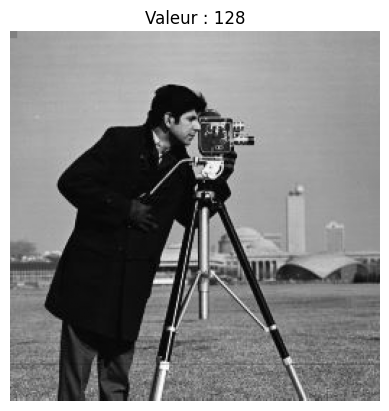

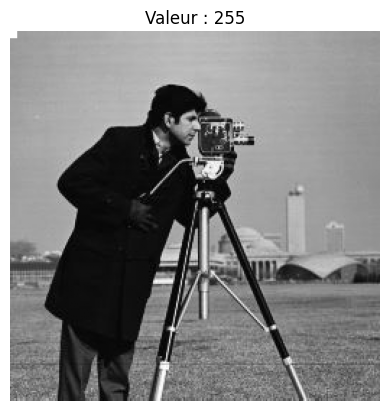

In [ ]:
valeurs = [0, 128, 255]

for v in valeurs :
  image_mod = image.copy()
  image_mod[0:5, 0:5] = v

  plt.imshow(image_mod, cmap='gray')
  plt.title(f"Valeur : {v}")
  plt.axis('off')  # Masquer les axes
  plt.show()

Questions d’analyse

Q1. Que représentent une ligne, une colonne et un élément de la matrice image ?

--> Une ligne ($i$) : L'axe vertical de l'image (coordonnée $y$), ordonné de haut en bas.Une colonne ($j$) : L'axe horizontal de l'image (coordonnée $x$), ordonné de gauche à droite.Un élément : Un pixel (picture element). Sa position $(i, j)$ définit sa localisation spatiale et sa valeur numérique représente son niveau de gris (intensité lumineuse).


Q2. Quelle différence existe-t-il entre une image en niveaux de gris et une image couleur ?

--> Image en niveaux de gris : Matrice à 2 dimensions ($M \times N$). Chaque pixel contient une seule valeur scalaire représentant la luminance.Image couleur (ex. RGB) : Matrice à 3 dimensions ($M \times N \times 3$). Chaque pixel est un vecteur de trois canaux (Rouge, Vert, Bleu) dont la combinaison définit la couleur finale.

Q3. Une image codée sur 8 bits contient-elle nécessairement les 256 niveaux de gris ?

--> Non. Un codage sur 8 bits signifie simplement que l'image peut exprimer au maximum $2^8 = 256$ nuances théoriques (valeurs entières de $0$ à $255$). L'image peut parfaitement n'utiliser qu'un sous-ensemble de ces valeurs (par exemple, une image à faible contraste ou binaire n'utilisera que quelques niveaux).

Q4. Distinguer le type de stockage des pixels et les valeurs réellement présentes.

--> Type de stockage (plage théorique) : Défini par le type de données (ex. uint8), il fixe l'intervalle des valeurs représentables dans la mémoire, soit $[0, 255]$ pour du 8 bits sans signe.Valeurs réellement présentes (dynamique observée) : L'ensemble des intensités effectives mesurables dans l'image, délimité par son minimum réel ($\text{min}$) et son maximum réel ($\text{max}$), tel que $[\text{min}, \text{max}] \subseteq [0, 255]$.

Pour la suite : effectuer les calculs arithmétiques en nombres réels afin d’éviter les effets du stockage
entier.

# **Exercice 2:**

Dans ce TP, la luminance moyenne désigne la moyenne des niveaux de gris, sans calibration
photométrique. Pour M × N pixels, on définit :



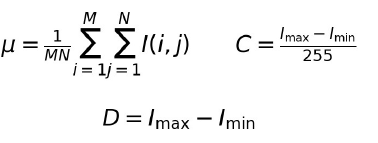




μ désigne la luminance moyenne. D est l’étendue observée. Le contraste C = D/255 est compris entre 0
et 1. Le nombre de niveaux est noté L = 256 ; la valeur maximale possible est L − 1 = 255.

1. Calculer μ, C et D pour cameraman.tif

APPAREMMENT FAUT CONVERTIR EN FLOAT LIMAGE AVEC CV2

In [ ]:
import numpy as np

mu = np.mean(image)
D = image.max() - image.min()
C = D / 255

print ("mu = ", mu)
print ("D = ", D)
print ("C = ", C)

mu =  118.72439575195312
D =  255.0
C =  1.0


2. Construire en nombres réels les trois images suivantes. (I représente la valeur du pixel)

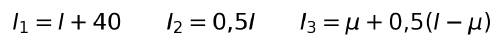

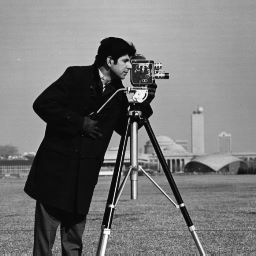

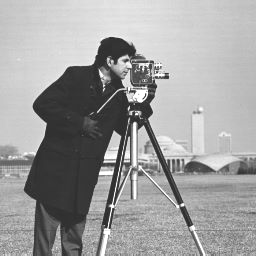

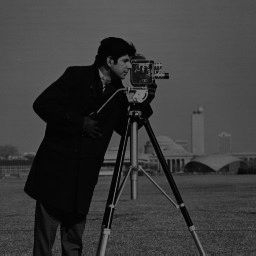

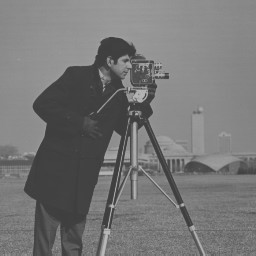

In [ ]:
import google.colab.patches
from google.colab.patches import cv2_imshow



image_1 = image.copy()
image_1 = image_1 + 40

image_2 = image.copy()
image_2 = image_2 * 0.5

image_3 = image.copy()
image_3 = mu + 0.5 * (image_3 - mu)

cv2_imshow(image)
cv2_imshow(image_1)
cv2_imshow(image_2)
cv2_imshow(image_3)






solution matplotlib qu'on a cherché 2h

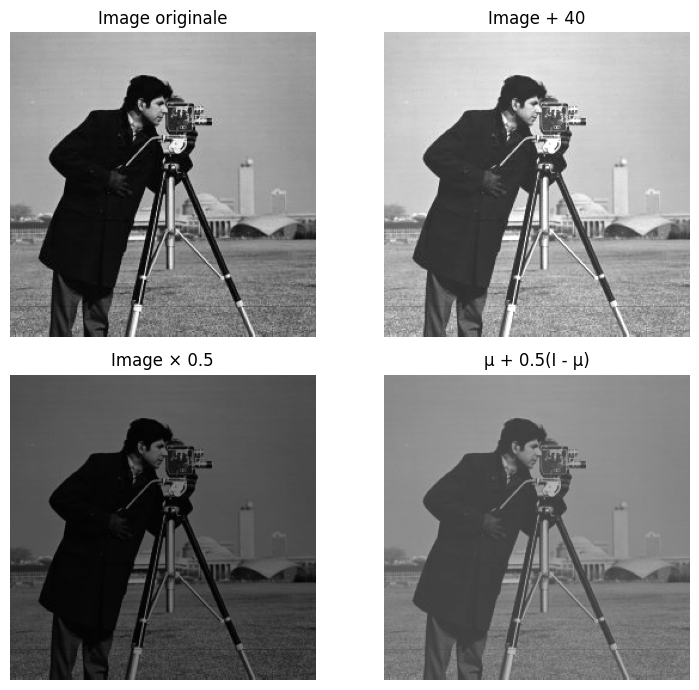

In [ ]:
plt.figure(figsize=(8, 7))
plt.subplot(2, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Image originale')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(image_1, cmap='gray', vmin=0, vmax=255)
plt.title('Image + 40')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.imshow(image_2, cmap='gray', vmin=0, vmax=255)
plt.title('Image × 0.5')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.imshow(image_3, cmap='gray', vmin=0, vmax=255)
plt.title('μ + 0.5(I - μ)')
plt.axis('off')
plt.tight_layout()
plt.show()

3. Pour chaque transformation, relever le minimum et le maximum avant êcretage

In [ ]:
print(f"Image originale : min = {image.min()} & max = {image.max()}")
print(f"Image 1 (+40) : min = {image_1.min()} & max = {image_1.max()}")
print(f"Image 2 (*0.5) : min = {image_2.min()} & max = {image_2.max()}")
print(f"Image 3 (mu + 0.5 * (image_3 - mu)) : min = {image_3.min()} & max = {image_3.max()}")

Image originale : min = 0.0 & max = 255.0
Image 1 (+40) : min = 40.0 & max = 295.0
Image 2 (*0.5) : min = 0.0 & max = 127.5
Image 3 (mu + 0.5 * (image_3 - mu)) : min = 59.36219787597656 & max = 186.86219787597656


4. Ecreter les valeurs dans [0, 255] : remplacer les valeurs négatives par 0 et celles supérieurs à 255 par 255. Compter les pixels modifiés.

In [ ]:
def ecretage(image):

  image_ecretee = image.copy()

  nb_pixel_modif= 0

  hauteur, largeur = image_ecretee.shape

  for i in range (hauteur):
    for j in range(largeur):
      if image_ecretee[i, j] < 0:
        image_ecretee[i, j] = 0
        nb_pixel_modif = nb_pixel_modif + 1
      elif image_ecretee[i, j] > 255:
        image_ecretee[i, j] = 255
        nb_pixel_modif = nb_pixel_modif + 1

  return image_ecretee, nb_pixel_modif

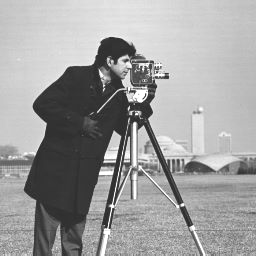

467


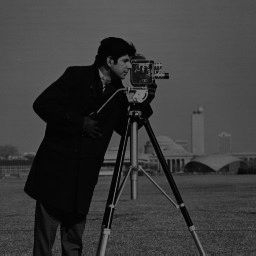

0


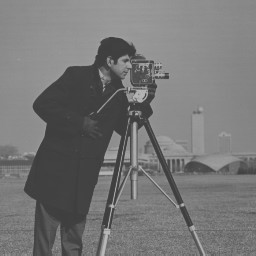

0


In [ ]:
image_1_ecretee, nb_modif_1 = ecretage(image_1)
cv2_imshow(image_1_ecretee)
print(nb_modif_1)

image_2_ecretee, nb_modif_2 = ecretage(image_2)
cv2_imshow(image_2_ecretee)
print(nb_modif_2)

image_3_ecretee, nb_modif_3 = ecretage(image_3)
cv2_imshow(image_3_ecretee)
print(nb_modif_3)



5. Afficher les images avec une échelle de gris commune fixée à [0, 255]. Compléter le tableau après
écrêtage, avant arrondi.

In [ ]:
#Images déja affichée juste avant

mu_1_ecretee = np.mean(image_1_ecretee)
D_1_ecretee = image_1_ecretee.max() - image_1_ecretee.min()
C_1_ecretee = D_1_ecretee / 255

mu_2_ecretee = np.mean(image_2_ecretee)
D_2_ecretee = image_2_ecretee.max() - image_2_ecretee.min()
C_2_ecretee = D_2_ecretee / 255

mu_3_ecretee = np.mean(image_3_ecretee)
D_3_ecretee = image_3_ecretee.max() - image_3_ecretee.min()
C_3_ecretee = D_3_ecretee / 255


print ("mu_1_ecretee = ", mu_1_ecretee)
print ("D_1_ecretee = ", D_1_ecretee)
print ("C_1_ecretee = ", C_1_ecretee)

print ("mu_2_ecretee = ", mu_2_ecretee)
print ("D_2_ecretee = ", D_2_ecretee)
print ("C_2_ecretee = ", C_2_ecretee)

print ("mu_3_ecretee = ", mu_3_ecretee)
print ("D_3_ecretee = ", D_3_ecretee)
print ("C_3_ecretee = ", C_3_ecretee)



mu_1_ecretee =  158.6007843017578
D_1_ecretee =  215.0
C_1_ecretee =  0.8431372549019608
mu_2_ecretee =  59.36219787597656
D_2_ecretee =  127.5
C_2_ecretee =  0.5
mu_3_ecretee =  118.72439575195312
D_3_ecretee =  127.5
C_3_ecretee =  0.5


Questions d'analyse:

Q1. Quelle transformation éclaircit l’image ? Laquelle diminue le contraste en conservant théoriquement la moyenne ?

--> Éclaircissement : L'addition d'une constante positive ($I_1 = I + c$) augmente tous les niveaux de gris et donc la luminance moyenne $\mu$.   Diminution de contraste à moyenne constante : La réduction de dynamique centrée sur la moyenne ($I_3 = c \cdot (I - \mu) + \mu$ avec $0 < c < 1$) resserre les valeurs autour de $\mu$, ce qui diminue l'étendue $D$ et le contraste $C$ tout en conservant théoriquement la valeur de $\mu$.   

Q3. Pourquoi l’écrêtage peut-il rendre ces relations inexactes ?

--> L'écrêtage remplace les valeurs $< 0$ par $0$ et $> 255$ par $255$. La suppression des valeurs extrêmes modifie la distribution des niveaux de gris : la luminance moyenne réelle $\mu$ s'éloigne de sa valeur théorique et le contraste observé $C$ se retrouve plafonné.

Q4. Une image plus claire est-elle nécessairement plus contrastée ?

--> Non. La clarté dépend uniquement de la luminance moyenne $\mu$. Le contraste $C$ dépend de la dispersion des niveaux de gris ($D/255$). Une image peut avoir une luminance élevée tout en présentant des niveaux de gris très resserrés (contraste faible).  


Q5. Pourquoi un affichage ajusté automatiquement à chaque image peut-il fausser la comparaison ?

--> Un affichage dynamique recadre automatiquement le noir sur la valeur minimale et le blanc sur la valeur maximale de l'image courante. Cela réalise un étirement visuel qui masque les différences réelles d'intensité et de contraste. Fixer l'échelle à $[0, 255]$ est indispensable pour comparer fidèlement les images.

# **Exercice 3 :**

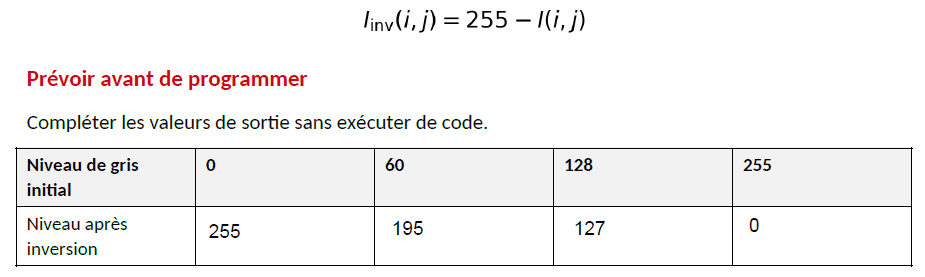

1. Calculer le négatif de cameraman.tif.

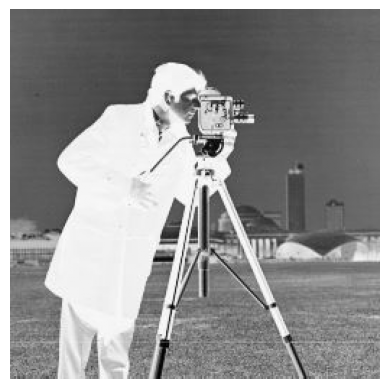

In [ ]:
image_neg = 1 - image
# Afficher l'image en niveaux de gris
plt.imshow(image_neg, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

2. Afficher l’image originale et son négatif côte à côte avec la même échelle [0, 255].

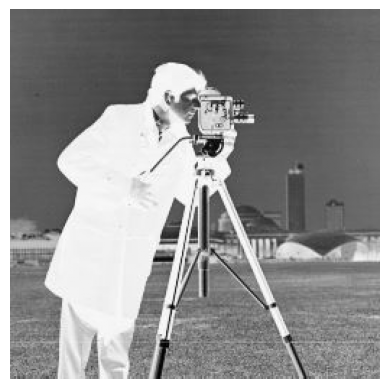

In [ ]:
# Afficher l'image originale et la négative
plt.imshow(image_neg, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

3. Mesurer la luminance moyenne, le contraste normalisé et l’étendue des deux images.

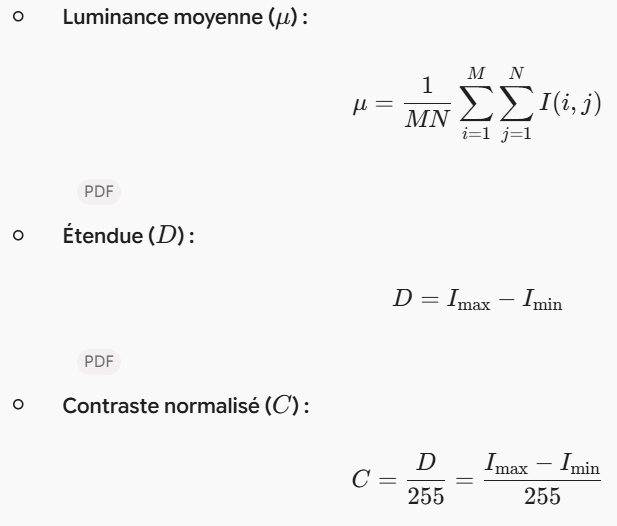

In [ ]:
import numpy as np

luminance_moyenne = np.mean(image)
luminance_moyenne_neg = np.mean(image_neg)

contraste = image.max() - image.min() / 255
contraste_neg = image_neg.max() - image_neg.min()

etendue = image.max() - image.min()
etendue_neg = image_neg.max() - image_neg.min()

print("etendue:", etendue)
print("etendue_neg:", etendue_neg)
print("contraste:", contraste)
print("contraste_neg:", contraste_neg)
print("luminence_moyenne:", luminance_moyenne)
print("luminence_moyenne_neg:", luminance_moyenne_neg)


etendue: 255.0
etendue_neg: 255.0
contraste: 255.0
contraste_neg: 255.0
luminence_moyenne: 118.72439575195312
luminence_moyenne_neg: -117.72439575195312


4. Appliquer une seconde inversion au négatif.

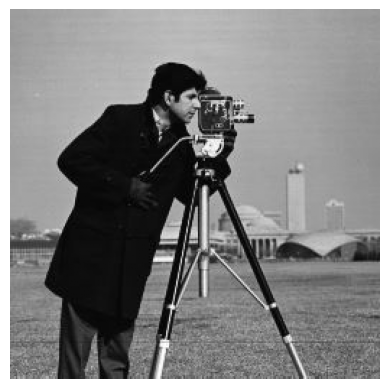

In [ ]:
image_double_neg = 1 - image_neg
# Afficher l'image en niveaux de gris
plt.imshow(image_double_neg, cmap='gray')
plt.axis('off')  # Masquer les axes
5. Comparer numériquement cette dernière image à l’originale : compter les pixels différents et calculer
l’écart absolu maximal.plt.show()

5. Comparer numériquement cette dernière image à l’originale : compter les pixels différents et calculer
l’écart absolu maximal.



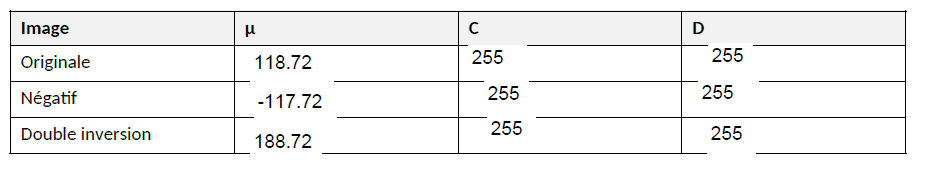

**Questions d'analyses:**


Q1. Décrire le devenir des zones sombres et des zones claires.


1. L'opération d'inversion est donnée par la formule $I_{\text{inv}}(i, j) = 255 - I(i, j)$.   Zones sombres : Leurs niveaux de gris $I(i, j)$ sont proches de $0$. Après inversion, leurs nouvelles valeurs deviennent proches de $255 - 0 = 255$, ce qui correspond à des zones claires (blanches).   Zones claires : Leurs niveaux de gris $I(i, j)$ sont proches de $255$. Après inversion, leurs nouvelles valeurs deviennent proches de $255 - 255 = 0$, ce qui correspond à des zones sombres (noires).   Résumé : Les zones sombres deviennent claires et les zones claires deviennent sombres. La dynamique visuelle est inversée.

Q2. Démontrer que la luminance du négatif vaut 255 − μ.

Démonstration :La luminance moyenne $\mu$ d'une image de dimensions $M \times N$ est définie par :$$\mu = \frac{1}{M N} \sum_{i=1}^{M} \sum_{j=1}^{N} I(i, j)$$   Pour l'image négative $I_{\text{inv}}$, la luminance moyenne $\mu_{\text{inv}}$ s'écrit :$$\mu_{\text{inv}} = \frac{1}{M N} \sum_{i=1}^{M} \sum_{j=1}^{N} I_{\text{inv}}(i, j)$$En remplaçant $I_{\text{inv}}(i, j)$ par $255 - I(i, j)$ :
   $$\mu_{\text{inv}} = \frac{1}{M N} \sum_{i=1}^{M} \sum_{j=1}^{N} \big(255 - I(i, j)\big)$$En séparant la somme par linéarité :$$\mu_{\text{inv}} = \frac{1}{M N} \sum_{i=1}^{M} \sum_{j=1}^{N} 255 - \frac{1}{M N} \sum_{i=1}^{M} \sum_{j=1}^{N} I(i, j)$$Puisque la somme d'une constante $255$ sur $M \times N$ pixels vaut $255 \times M N$ :$$\mu_{\text{inv}} = \frac{255 \times M N}{M N} - \mu = 255 - \mu$$Conclusion : La luminance moyenne du négatif est bien égale à $255 - \mu$.
  

Q3. Montrer que le contraste normalisé et l’étendue restent inchangés.

Démonstration :

Soient $I_{\min}$ et $I_{\max}$ les valeurs minimale et maximale des pixels de l'image originale $I$.
Pour l'image négative

$I_{\text{inv}} = 255 - I$ :   

La valeur maximale devient $I_{\text{inv, max}} = 255 - I_{\min}$

La valeur minimale devient $I_{\text{inv, min}} = 255 - I_{\max}$

Étendue:

($D_{\text{inv}}$) :$$D_{\text{inv}} = I_{\text{inv, max}} - I_{\text{inv, min}} = (255 - I_{\min}) - (255 - I_{\max}) = I_{\max} - I_{\min} = D$$   

Contraste normalisé:

($C_{\text{inv}}$) :$$C_{\text{inv}} = \frac{D_{\text{inv}}}{255} = \frac{D}{255} = C$$   

Conclusion : L'étendue $D$ et le contraste normalisé $C$ restent exactement identiques.


Q4. Pourquoi les images paraissent-elles différentes malgré un contraste normalisé identique ?

Explication :
Le contraste normalisé $C$ et l'étendue $D$ ne mesurent que l'écart global d'amplitude entre le pixel le plus clair et le plus sombre ($I_{\max} - I_{\min}$). Ils ne prennent pas en compte la distribution spatiale des pixels ni la polarité des intensités.   Le système visuel humain perçoit principalement la brillance relative des structures par rapport à leur arrière-plan. Bien que l'amplitude globale des intensités reste constante, l'inversion modifie la luminance moyenne ($\mu_{\text{inv}} = 255 - \mu$) et permute le fond et les objets, ce qui donne une perception visuelle complètement différente.

Q5. L’inversion provoque-t-elle une perte d’information ? Justifier à partir des calculs et de la double
inversion.

Explication :

Non, l'inversion ne provoque aucune perte d'information.

Justification :

Bijection mathématique :

La fonction $f(x) = 255 - x$ est strictement bijective (injective et surjective) sur l'ensemble $\{0, \dots, 255\}$. Deux niveaux de gris distincts dans l'image originale donneront obligatoirement deux niveaux de gris distincts dans le négatif.

Involutivité (Double inversion) :

Si l'on applique l'inversion une seconde fois sur le négatif :


   $$I_{\text{double}}(i, j) = 255 - I_{\text{inv}}(i, j) = 255 - (255 - I(i, j)) = I(i, j)$$
   
Vérification numérique : L'écart absolu maximal entre l'image doublement inversée et l'image originale est de $0$, et le nombre de pixels différents est égal à $0$. L'image de départ est donc intégralement conservée.

# **Exercice 4 :**

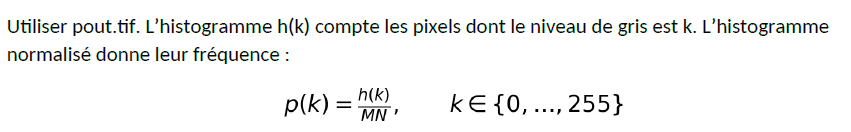

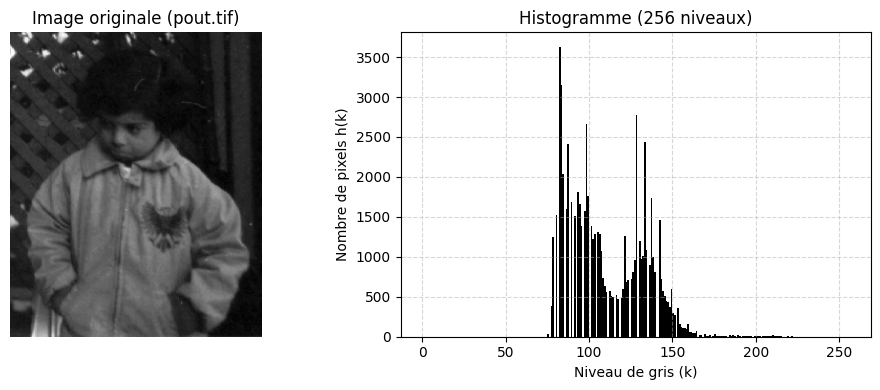

In [ ]:
# Charger l'image cameraman intégrée dans skimage
pout = cv2.imread("/content/drive/MyDrive/Traitement d'images/pout.tif", cv2.IMREAD_GRAYSCALE)

#préparer un graph où on va mettre les 2 dessus
plt.figure(figsize=(10, 4))

# Affichage de l'image
plt.subplot(1, 2, 1)
plt.imshow(pout, cmap='gray')
plt.title("Image originale (pout.tif)")
plt.axis('off')

# Affichage de l'histogramme sur 256 niveaux (bins)
plt.subplot(1, 2, 2)
plt.hist(pout.ravel(), bins=256, range=(0, 256), color='black') #ravel transforme en vecteur
plt.title("Histogramme (256 niveaux)")
plt.xlabel("Niveau de gris (k)")
plt.ylabel("Nombre de pixels h(k)")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

2. Construire l’histogramme sans fonction dédiée : initialiser 256 compteurs, parcourir les pixels et
incrémenter le compteur correspondant. Attention : les indices commencent à 1 sous MATLAB et à 0
sous Python.

hauteur :  291
largeur : 240


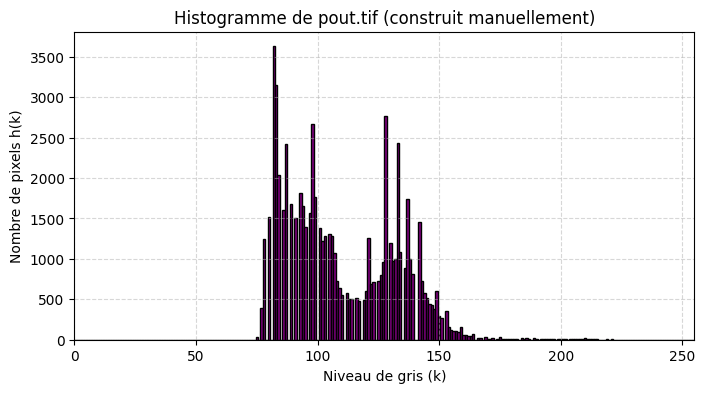

In [ ]:
height, width = pout.shape
print("hauteur : ", height)
print("largeur :", width)

# 2. Initialiser un tableau de 256 compteurs à zéro
h_manuel = np.zeros(256, dtype=int)

# 3. Parcourir chaque pixel et incrémenter le compteur correspondant
for i in range(height):
    for j in range(width):
        k = pout[i, j]      # Valeur du niveau de gris (entre 0 et 255)
        h_manuel[int(k)] += 1   # L'indice k va de 0 à 255

#DESSIN HISTGRAMME A LA MAIN
# Les niveaux de gris vont de 0 à 255
niveaux = range(256)

plt.figure(figsize=(8, 4))

# Style bâtons / barres pour un histogramme classique
plt.bar(niveaux, h_manuel, width=1.0, color='purple', edgecolor='black')

plt.title("Histogramme de pout.tif (construit manuellement)")
plt.xlabel("Niveau de gris (k)")
plt.ylabel("Nombre de pixels h(k)")
plt.xlim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

3. Comparer les compteurs au résultat d’une fonction de bibliothèque.

In [ ]:
import cv2

#2. Histogramme avec la bibliothèque OpenCV
h_biblio = cv2.calcHist([pout], [0], None, [256], [0, 256]).ravel().astype(int) #image, indice du canal (0=gris), pas de masque, nb d'intervalle, plage, applati en vecteur, converti en int pour comparaison

# 3. Comparaison numérique
ecart_max = np.max(np.abs(h_manuel - h_biblio))
nb_differences = np.count_nonzero(h_manuel != h_biblio)
'''
h_manuel != h_biblio : Renvoie un tableau de booléens
(True aux indices où le comptage diffère, False là
où il est identique).

np.count_nonzero(...) : Compte le nombre
d'éléments True. S'il vaut 0, aucun niveau
de gris ne présente de différence.
'''
identiques = np.array_equal(h_manuel, h_biblio) #np.allclose marche aussi

print(f"Écart absolu maximal entre compteurs : {ecart_max}")
print(f"Nombre de niveaux avec différences : {nb_differences}")
print(f"Les deux histogrammes sont-ils identiques ? {identiques}")

Écart absolu maximal entre compteurs : 0
Nombre de niveaux avec différences : 0
Les deux histogrammes sont-ils identiques ? True


4. Normaliser l’histogramme et vérifier les deux relations suivantes.

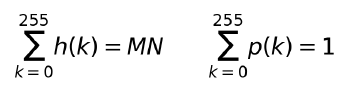

L'histogramme normalisé $p(k)$ donne la fréquence d'apparition de chaque niveau de gris $k$ :$$p(k) = \frac{h(k)}{M N}$$   Les deux relations à vérifier sont :

Somme des compteurs non normalisés :$$\sum_{k=0}^{255} h(k) = M N \quad \text{(égal au nombre total de pixels de l'image)}$$   

Somme des fréquences normalisées :$$\sum_{k=0}^{255} p(k) = 1 \quad \text{(la somme des probabilités est égale à 1)}$$

In [ ]:
MN = height * width

In [ ]:
# 2. Histogramme brut h(k) et histogramme normalisé p(k)
h = np.zeros(256, dtype=int)
for i in range(height):
    for j in range(width):
        h[pout[i, j]] += 1

p = h / MN  # Normalisation (frequences)

# 3. Vérification des relations
somme_h = np.sum(h)
somme_p = np.sum(p)

print(f"Nombre total de pixels (M x N) : {MN}")
print(f"1. Somme des h(k)               : {somme_h} -> Vérifié : {somme_h == MN}")
print(f"2. Somme des p(k)               : {somme_p:.6f} -> Vérifié : {np.isclose(somme_p, 1.0)}")

Nombre total de pixels (M x N) : 69840
1. Somme des h(k)               : 69840 -> Vérifié : True
2. Somme des p(k)               : 1.000000 -> Vérifié : True


5. Retrouver la luminance moyenne à partir de l’histogramme. Repérer le premier et le dernier niveau
dont le compteur est non nul, puis calculer D et C. Comparer aux calculs directs sur les pixels.

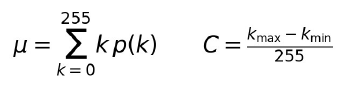

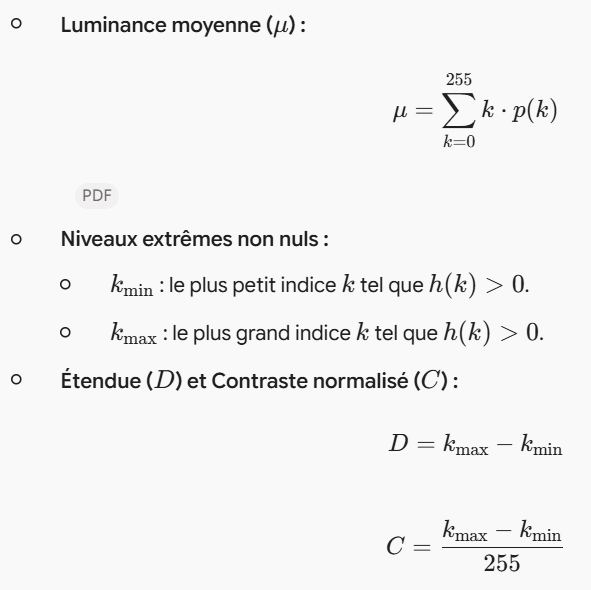

In [ ]:
#Calculs direct sur les pixels (pour comparaison)
mu_direct = np.mean(pout)
k_min_direct = np.min(pout)
k_max_direct = np.max(pout)
D_direct = k_max_direct - k_min_direct
C_direct = D_direct / 255.0

In [ ]:
#Calculs via l'histogramme
k_indices = np.arange(256)
mu_histo = np.sum(k_indices * p)

#Repérer les indices où le compteur est non nul
indices_non_nuls = np.where(h > 0)[0]
k_min_histo = indices_non_nuls[0] #[0] = 1er élément tableau
k_max_histo = indices_non_nuls[-1] #[-1] = dernier élément du tableau

'''
h > 0 : Crée un tableau de booléens de taille 256.
Il vaut True pour les niveaux de gris $k$ où au moins
 un pixel est présent ($h(k) > 0$), et False là où
 le niveau de gris est absent ($h(k) = 0$).np.where(...) :
  Cherche tous les indices où la condition est vraie (True).
  En NumPy, cette fonction renvoie un tuple de tableaux
  d'indices (un par dimension).[0] : Comme h est un tableau
  1D à une seule dimension, on extrait le premier
  (et unique) élément du tuple pour récupérer un
  simple tableau contenant la liste des niveaux de gris
  réellement présents dans l'image.
'''

D_histo = k_max_histo - k_min_histo
C_histo = D_histo / 255.0

In [ ]:
print("--- Comparaison des résultats ---")
print(f"Luminance μ : Direct = {mu_direct:.4f} | Histo = {mu_histo:.4f}")
print(f"k_min       : Direct = {k_min_direct} | Histo = {k_min_histo}")
print(f"k_max       : Direct = {k_max_direct} | Histo = {k_max_histo}")
print(f"Étendue D   : Direct = {D_direct} | Histo = {D_histo}")
print(f"Contraste C : Direct = {C_direct:.4f} | Histo = {C_histo:.4f}")

--- Comparaison des résultats ---
Luminance μ : Direct = 110.3037 | Histo = 110.3037
k_min       : Direct = 74 | Histo = 74
k_max       : Direct = 224 | Histo = 224
Étendue D   : Direct = 150 | Histo = 150
Contraste C : Direct = 0.5882 | Histo = 0.5882


6. Mélanger aléatoirement les positions des pixels sans modifier leurs valeurs. Reformer une image de
mêmes dimensions ; afficher le résultat et son histogramme.

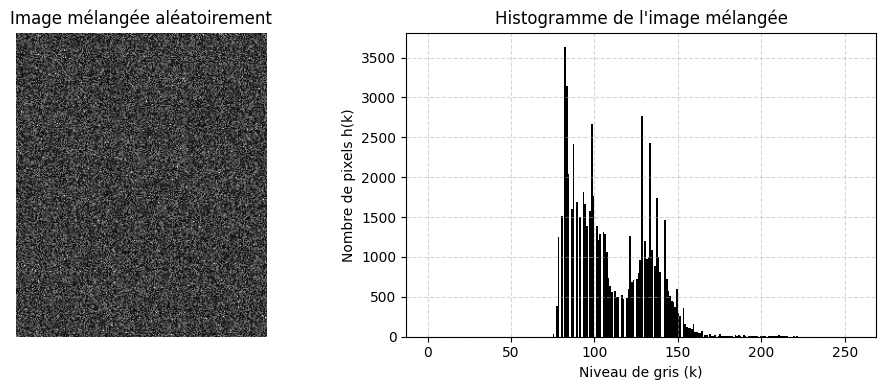

In [ ]:
#Aplatir l'image en 1D, mélanger les pixels, puis restructurer en 2D
shape_orig = pout.shape
pixels = pout.ravel().copy()
np.random.shuffle(pixels)
pout_melangee = pixels.reshape(shape_orig)

#Affichage de l'image mélangée et de son histogramme
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(pout_melangee, cmap='gray')
plt.title("Image mélangée aléatoirement")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(pout_melangee.ravel(), bins=256, range=(0, 256), color='black')
plt.title("Histogramme de l'image mélangée")
plt.xlabel("Niveau de gris (k)")
plt.ylabel("Nombre de pixels h(k)")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Questions d'analyses:

Q1. Que suggère un histogramme concentré vers les faibles niveaux ? Vers les niveaux élevés ?

Concentré vers les faibles niveaux (proche de $0$) : L'image comporte une grande majorité de pixels sombres. Elle est globale et visuellement sous-exposée ou très sombre.   

Concentré vers les niveaux élevés (proche de $255$) : L'image comporte une grande majorité de pixels clairs. Elle est globale et visuellement sur-exposée ou très claire.  

Q2. Que suggère un histogramme concentré sur un intervalle étroit ?

Un histogramme concentré sur un intervalle étroit signifie que la différence entre le niveau de gris le plus faible ($k_{\min}$) et le plus élevé ($k_{\max}$) est faible.   Cela indique une étendue $D$ réduite et un contraste faible. L'image manque de dynamiques entre le sombre et le clair, ce qui lui donne un aspect terne, grisâtre ou « délavé », où les détails sont difficiles à distinguer (comme sur pout.tif).

Q3. L’histogramme permet-il de localiser les objets dans l’image ?

Non, absolument pas.L'histogramme est un outil statistique global qui compte uniquement le nombre global de pixels associés à chaque niveau de gris $k$, sans conserver leur position spatiale $(i, j)$ dans la matrice image. Il indique combien de pixels possèdent une certaine valeur, mais pas où ils se trouvent.

Q4. Pourquoi le mélange des pixels conserve-t-il l’histogramme, la moyenne et le contraste normalisé ?

Le mélange aléatoire n'est qu'une permutation spatiale des pixels.   Histogramme $h(k)$ : La quantité de pixels associés à chaque valeur de niveau de gris $k$ reste strictement identique.   Luminance moyenne $\mu$ : Calculée par $\mu = \frac{1}{MN}\sum I(i,j)$ ou $\mu = \sum k \cdot p(k)$, elle dépend uniquement des valeurs de l'ensemble des pixels, pas de leur ordonnancement spatiale.   Contraste $C$ et étendue $D$ : Les valeurs minimales ($k_{\min}$) et maximales ($k_{\max}$) restent inchangées dans le tableau, donc $D = k_{\max} - k_{\min}$ et $C = \frac{D}{255}$ restent identiques.

Q5. Ces indicateurs suffisent-ils à décrire la qualité visuelle d’une image ? Justifier à partir de l’image
mélangée.

Non, ces indicateurs ne suffisent pas du tout à décrire la qualité visuelle ou le contenu d'une image.Justification :
L'image mélangée aléatoirement possède exactement la même luminance moyenne ($\mu$), le même contraste ($C$) et le même histogramme que l'image originale pout.tif. Pourtant, l'image mélangée ne ressemble plus qu'à un bruit aléatoire inexploitable (bruit de neige), alors que l'image originale représente un objet reconnaissable.   La qualité visuelle et l'information utile d'une image dépendent principalement des relations spatiales entre pixels voisins (contours, textures, formes, structures), des informations que ces indicateurs globaux ignorent complètement.

# **Exercice 5:**

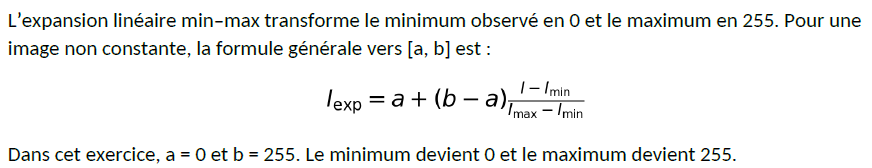

1. Implémenter la formule sur pout.tif en nombres réels, puis arrondir et convertir sur 8 bits.

In [ ]:
pout_float = pout.astype(float)

#relever min et max
I_max = pout_float.max()
I_min = pout_float.min()

#calcul de l'expension:

I_exp_float = 0.0 + (255.0 - 0.0) * ((pout - I_min) / (I_max - I_min))

#arrondir et convertir:
I_exp = np.round(I_exp_float).astype(np.uint8)
print(I_exp)

[[56 58 56 ... 17 15 15]
 [60 54 58 ... 17 17 20]
 [56 54 61 ... 17 15 15]
 ...
 [39 42 46 ... 14 14 15]
 [42 41 41 ... 17 17 20]
 [46 42 42 ... 39 39 39]]


2. Afficher l’image obtenue et son histogramme. Comparer μ, C et D avant et après traitement.

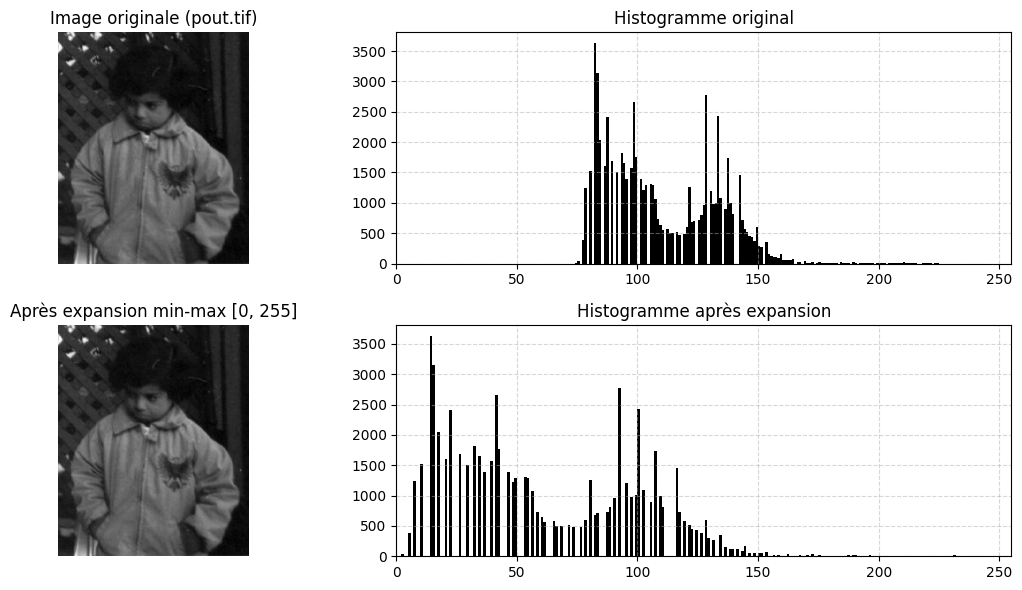

In [ ]:
#Affichage des images et des histogrammes ---
plt.figure(figsize=(12, 6))

# Image originale
plt.subplot(2, 2, 1)
plt.imshow(pout, cmap='gray')
plt.title("Image originale (pout.tif)")
plt.axis('off')

# Histogramme original
plt.subplot(2, 2, 2)
plt.hist(pout.ravel(), bins=256, range=(0, 256), color='black')
plt.title("Histogramme original")
plt.xlim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)

# Image étirée (Expansion min-max)
plt.subplot(2, 2, 3)
plt.imshow(I_exp, cmap='gray')
plt.title("Après expansion min-max [0, 255]")
plt.axis('off')

# Histogramme étiré
plt.subplot(2, 2, 4)
plt.hist(I_exp.ravel(), bins=256, range=(0, 256), color='black')
plt.title("Histogramme après expansion")
plt.xlim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
#  Calcul et comparaison de μ, C et D
# Avant expansion
mu_orig = np.mean(pout_float)
D_orig = I_max - I_min
C_orig = D_orig / 255.0

# Après expansion (sur les valeurs réelles I_exp_float avant arrondi)
I_exp_min = I_exp_float.min()
I_exp_max = I_exp_float.max()

mu_exp = np.mean(I_exp_float)
D_exp = I_exp_max - I_exp_min
C_exp = D_exp / 255.0

print(f"--- COMPARAISE DES INDICATEURS ---")
print(f"Originale -> μ: {mu_orig:.2f} | D: {D_orig:.0f} | C: {C_orig:.4f}")
print(f"Expansée  -> μ: {mu_exp:.2f} | D: {D_exp:.0f} | C: {C_exp:.4f}")

--- COMPARAISE DES INDICATEURS ---
Originale -> μ: 110.30 | D: 150 | C: 0.5882
Expansée  -> μ: 61.72 | D: 255 | C: 1.0000


Étendue $D$ et Contraste $C$ :

L'étendue passe à $255$ et le contraste normalisé passe à $1,0$ (valeur maximale possible).

L'histogramme s'est étalé sur toute la plage disponible $[0, 255]$.   

Luminance moyenne $\mu$ : Elle est modifiée car le décalage et l'étirement des niveaux rééquilibrent la moyenne par rapport au nouvel intervalle $[0, 255]$.   

Visuel : L'image est beaucoup plus lisible et les détails ressortent davantage grâce à la dynamique augmentée

3. Tracer la fonction de transformation : niveau d’entrée en abscisse et niveau de sortie en ordonnée.

le but c'est de montrer la différence de variation entre l'image normale et celle où la dynamique est expensée

/tmp/ipykernel_1163/3600083580.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


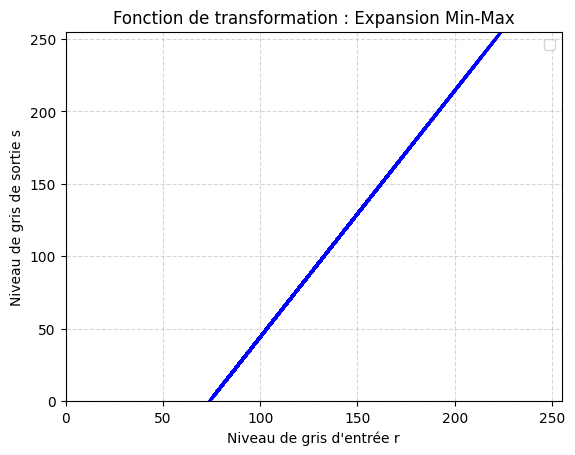

In [ ]:
plt.plot(pout, I_exp_float, color='blue', linewidth=2)
plt.plot([0, 255], [0, 255], color='gray', linestyle='--', label="Identité (sans traitement)")

plt.title("Fonction de transformation : Expansion Min-Max")
plt.xlabel("Niveau de gris d'entrée r")
plt.ylabel("Niveau de gris de sortie s")
plt.xlim([0, 255])
plt.ylim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.show()

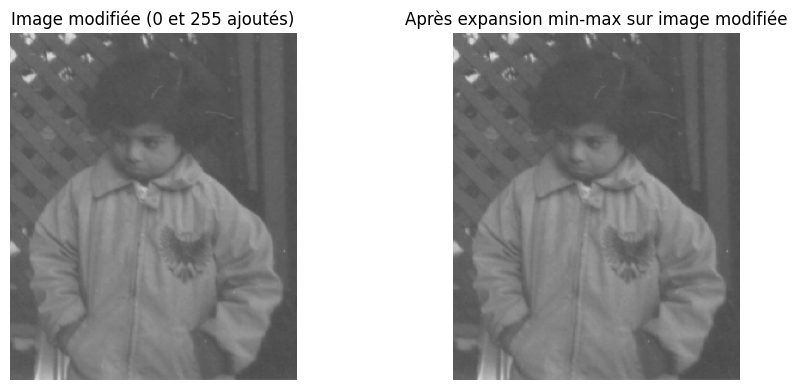

I_min observé : 0.0, I_max observé : 255.0


In [ ]:
#Créer une copie et modifier deux pixels isolés
pout_bruitee = pout.copy()
pout_bruitee[0, 0] = 0      # Pixel tout noir
pout_bruitee[0, 1] = 255    # Pixel tout blanc

#Refaire l'expansion min-max sur cette image modifiée
pout_bruitee_float = pout_bruitee.astype(float)
I_min = pout_bruitee_float.min()  # Vaut désormais 0
I_max = pout_bruitee_float.max()  # Vaut désormais 255

I_exp_bruitee_float = 0.0 + (255.0-0.0) * (pout_bruitee_float - I_min) / (I_max - I_min)
I_exp_bruitee = np.round(I_exp_bruitee_float).astype(np.uint8)

#Affichage pour comparaison
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(pout_bruitee, cmap='gray')
plt.title("Image modifiée (0 et 255 ajoutés)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(I_exp_bruitee, cmap='gray')
plt.title("Après expansion min-max sur image modifiée")
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"I_min observé : {I_min}, I_max observé : {I_max}")

In [ ]:
sont_identiques = np.array_equal(pout_bruitee, I_exp_bruitee)
print(f"Les deux images sont-elles identiques ? {sont_identiques}")

Les deux images sont-elles identiques ? True


Questions d'analyses:


Q1. Pourquoi l’expansion min–max est-elle sensible aux pixels extrêmes ?

L'expansion min–max dépend exclusivement de deux valeurs sur toute l'image :

$I_{\min}$ et $I_{\max}$.

Si seulement un pixel vaut $0$ et un autre vaut $255$ (dus à un bruit parasite ou un artefact de numérisation), ces deux valeurs deviennent directement $I_{\min}$ et $I_{\max}$.

La transformation se réduit alors à :$$I_{\text{exp}} = 255 \times \frac{I - 0}{255 - 0} = I$$

Deux seuls pixels isolés suffisent ainsi à paralyser complètement l'étirement du contraste du reste de l'image.

Q2. Quel avantage apporte l’utilisation des percentiles ? Quelle information peut-elle supprimer ?

Avantage : Elle apporte de la robustesse. En ignorant une petite fraction de pixels aux extrémités (ex. $1\%$ à $5\%$ inférieurs et supérieurs avec $P_{1}$ et $P_{99}$), la transformation n'est plus verrouillée par le bruit impulsif et parvient à étirer efficacement le contraste de la grande majorité de l'image.Information supprimée : Tous les pixels d'origine situés en dessous de $P_{1}$ sont saturés à $0$ (noir) et ceux au-dessus de $P_{99}$ à $255$ (blanc). On perd ainsi la nuance des détails dans les zones très sombres ou très claires (écrêtage / clipping).


Q3. L’expansion rend-elle l’histogramme uniforme ? Expliquer.

Non. L'expansion min–max est une transformation affine (linéaire).

Elle se contente de décaler et de dilater (écarter) les bâtons de l'histogramme sans modifier la forme de leur distribution relative ni rééquilibrer le nombre de pixels par niveau de gris. Pour obtenir un histogramme plat/uniforme, il faut utiliser une technique non linéaire comme l'égalisation d'histogramme.


Q4. Que faut-il prévoir lorsque tous les pixels ont la même valeur ?


Si l'image est uniforme (ex. tous les pixels valent $128$), alors $I_{\min} = I_{\max}$.Problème : La formule $255 \times \frac{I - I_{\min}}{I_{\max} - I_{\min}}$ provoque une division par zéro.Solution à prévoir : Insérer un test conditionnel dans le code : si $I_{\max} == I_{\min}$, ignorer l'expansion et retourner l'image inchangée (ou une image uniforme de valeur fixe, par exemple $0$ ou $128$) pour éviter une erreur d'exécution (NaN / Inf).

Q5. L’expansion peut-elle aussi rendre le bruit plus visible ? Pourquoi ?

Oui, absolument.En étirant la plage dynamique, la pente de la transformation $\frac{255}{I_{\max} - I_{\min}}$ est supérieure à $1$. Elle amplifie l'écart entre des niveaux de gris proches. Si l'image originale contenait un bruit de fond faible (ex. des variations légères de niveaux entre $100$ et $105$), cet écart sera étalé sur une plage beaucoup plus large (ex. entre $0$ et $25$), rendant ce bruit de fond nettement plus contrasté et visible à l'œil nu.

# **Exercice 6:**

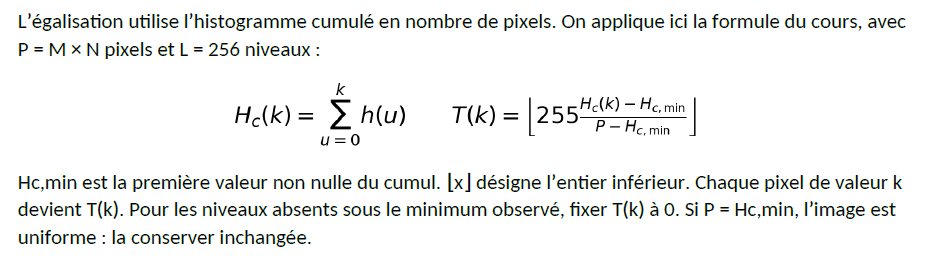

1. Calculer l’histogramme h de pout.tif en nombre de pixels.

In [ ]:
#Calcul manuel de h(k)
h = np.zeros(256, dtype=int)
for pixel in pout.ravel():
    h[pixel] += 1

# Vérification : la somme de h doit être égale au nombre total de pixels (M x N)
print(f"Nombre total de pixels (M x N) : {pout.size}")
print(f"Somme de l'histogramme sum(h) : {np.sum(h)}")

Nombre total de pixels (M x N) : 69840
Somme de l'histogramme sum(h) : 69840


2. Calculer le cumul Hc, vérifier que Hc(255) = P et déterminer Hc,min.

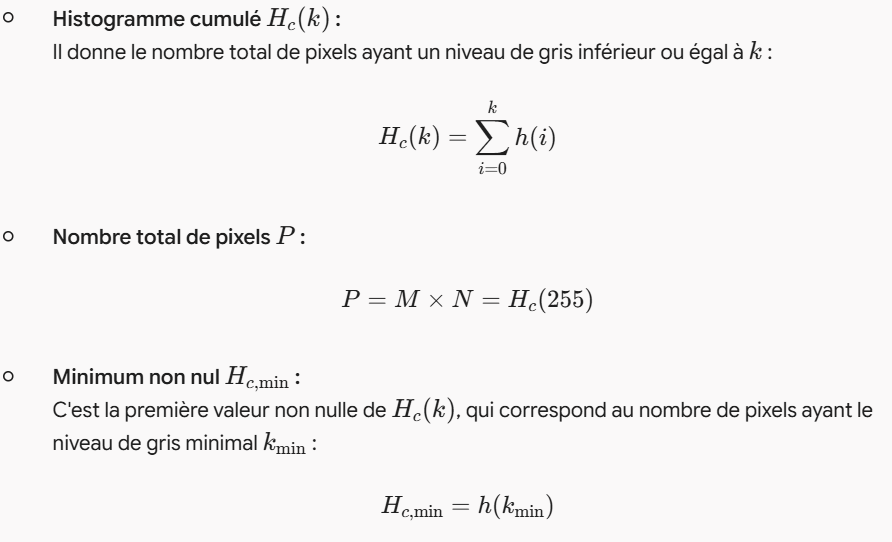

In [ ]:
P = pout.size #MN

#Calcul de l'histogramme cumulé Hc
Hc = np.cumsum(h)

#Détermination de Hc_min (première valeur non nulle de Hc)
#Méthode : première valeur de Hc strictement supérieure à 0
Hc_min = Hc[Hc > 0][0]

# --- Vérifications et affichages ---
print(f"Nombre total de pixels P : {P}")
print(f"Hc(255)                  : {Hc[255]}")
print(f"Vérification Hc(255) == P: {Hc[255] == P}")
print(f"Hc_min                   : {Hc_min}")

Nombre total de pixels P : 69840
Hc(255)                  : 69840
Vérification Hc(255) == P: True
Hc_min                   : 2


3. Tracer Hc(k), puis la transformation T(k).

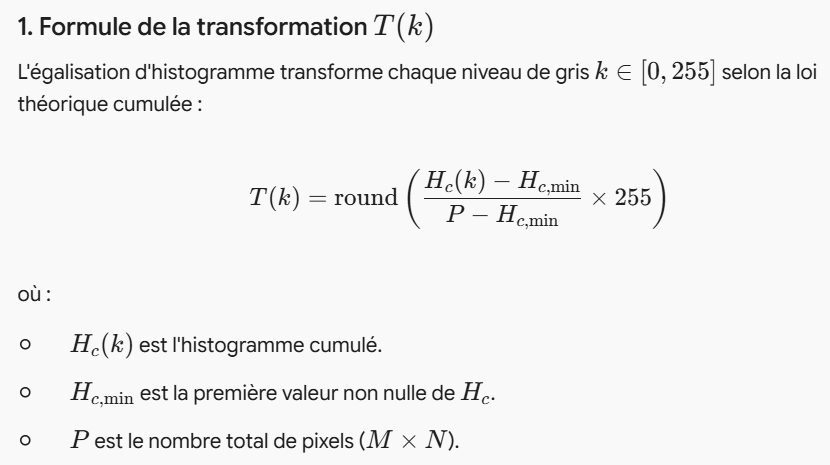

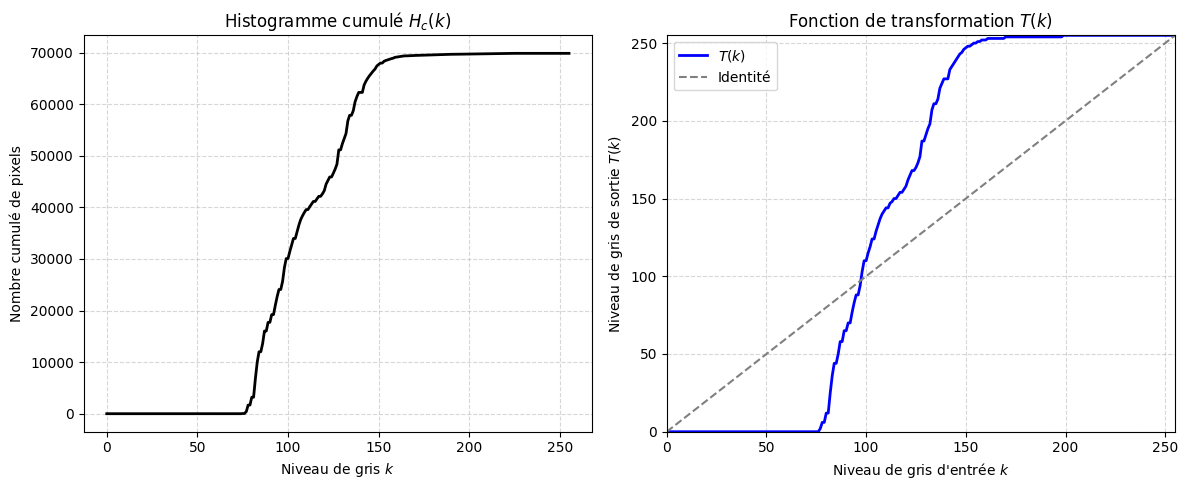

In [ ]:
k = np.arange(256)
T = np.round(((Hc - Hc_min) / (P - Hc_min)) * 255.0).astype(np.uint8)

#Tracé de Hc(k) et T(k)
plt.figure(figsize=(12, 5))

#Graphique 1 : Histogramme cumulé Hc(k)
plt.subplot(1, 2, 1)
plt.plot(k, Hc, color='black', linewidth=2)
plt.title("Histogramme cumulé $H_c(k)$")
plt.xlabel("Niveau de gris $k$")
plt.ylabel("Nombre cumulé de pixels")
plt.grid(True, linestyle='--', alpha=0.5)

#Graphique 2 : Fonction de transformation T(k)
plt.subplot(1, 2, 2)
plt.plot(k, T, color='blue', linewidth=2, label="$T(k)$")
plt.plot([0, 255], [0, 255], color='gray', linestyle='--', label="Identité")
plt.title("Fonction de transformation $T(k)$")
plt.xlabel("Niveau de gris d'entrée $k$")
plt.ylabel("Niveau de gris de sortie $T(k)$")
plt.xlim([0, 255])
plt.ylim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

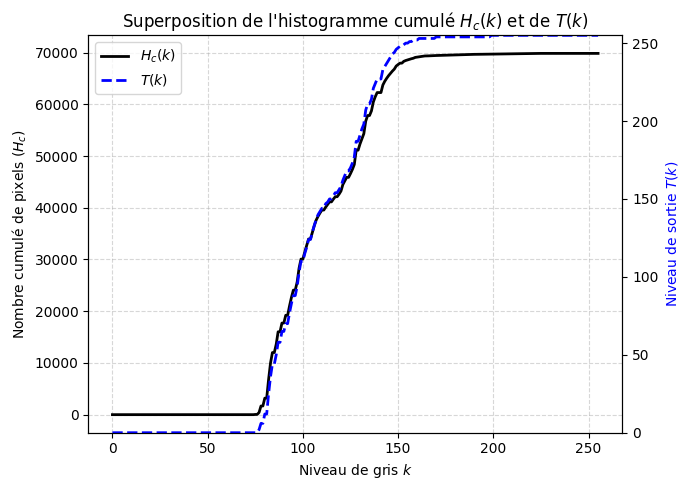

In [ ]:
# Graphique de superposition Hc(k) et T(k) avec double axe Y
fig, ax1 = plt.subplots(figsize=(7, 5))

# Axe de gauche : Hc(k)
l1 = ax1.plot(k, Hc, color='black', linewidth=2, label="$H_c(k)$")
ax1.set_xlabel("Niveau de gris $k$")
ax1.set_ylabel("Nombre cumulé de pixels ($H_c$)", color='black')
ax1.grid(True, linestyle='--', alpha=0.5)

# Axe de droite : T(k)
ax2 = ax1.twinx()
l2 = ax2.plot(k, T, color='blue', linewidth=2, linestyle='--', label="$T(k)$")
ax2.set_ylabel("Niveau de sortie $T(k)$", color='blue')
ax2.set_ylim([0, 255])

# Combinaison des légendes sur un seul bloc
lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title("Superposition de l'histogramme cumulé $H_c(k)$ et de $T(k)$")
plt.tight_layout()
plt.show()

4. Réaliser l’égalisation en appliquant cette table de correspondance aux pixels.

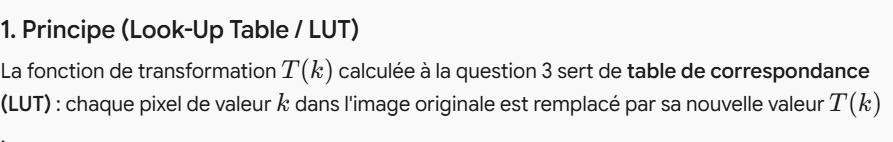

In [ ]:
# 1. Application manuelle de la LUT par indexation directe NumPy
# T est un tableau 1D de 256 éléments (uint8)
pout_eq = T[pout]

# Vérification du type et de la taille
print(f"Forme de l'image égalisée : {pout_eq.shape}")
print(f"Type de données           : {pout_eq.dtype}")
print(f"Plage de valeurs          : min = {pout_eq.min()}, max = {pout_eq.max()}")

Forme de l'image égalisée : (291, 240)
Type de données           : uint8
Plage de valeurs          : min = 0, max = 255


(np.float64(-0.5), np.float64(239.5), np.float64(290.5), np.float64(-0.5))

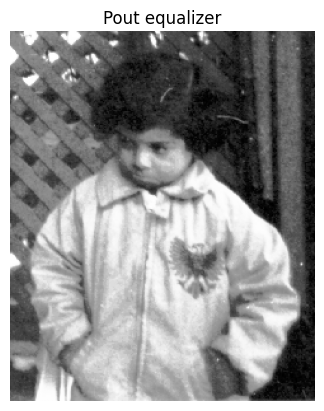

In [ ]:

plt.imshow(pout_eq, cmap='gray')
plt.title("Pout equalizer")
plt.axis('off')

5. Comparer le résultat à histeq(I, 256) sous MATLAB et à cv2.equalizeHist(image) sous Python. Ces
fonctions peuvent utiliser des conventions différentes. Comparer les écarts sans exiger une identité pixel
par pixel.

--- COMPARAISON MANUELLE vs OPENCV ---
Écart maximal         : 0 niveau(x)
Écart moyen           : 0.0000 niveaux
Pixels différents     : 0 / 69840 (0.00%)


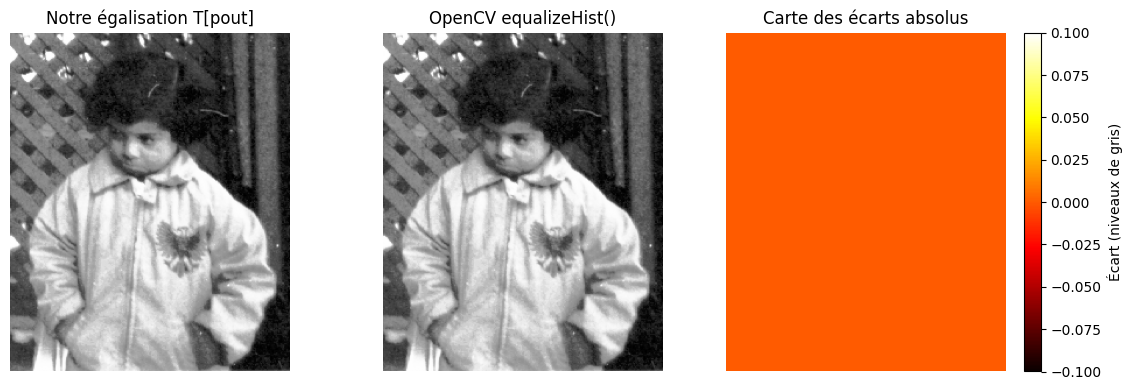

In [ ]:
# 1. Égalisation native OpenCV
pout_cv2 = cv2.equalizeHist(pout)

# 2. Comparaison numérique des résultats
diff_abs = np.abs(pout_eq.astype(int) - pout_cv2.astype(int))
ecart_max = np.max(diff_abs)
ecart_moyen = np.mean(diff_abs)
nb_pixels_diff = np.count_nonzero(diff_abs)
pct_diff = (nb_pixels_diff / pout.size) * 100

print("--- COMPARAISON MANUELLE vs OPENCV ---")
print(f"Écart maximal         : {ecart_max} niveau(x)")
print(f"Écart moyen           : {ecart_moyen:.4f} niveaux")
print(f"Pixels différents     : {nb_pixels_diff} / {pout.size} ({pct_diff:.2f}%)")

# 3. Affichage visuel des deux images et de la carte des différences
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(pout_eq, cmap='gray', vmin=0, vmax=255)
plt.title("Notre égalisation T[pout]")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(pout_cv2, cmap='gray', vmin=0, vmax=255)
plt.title("OpenCV equalizeHist()")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(diff_abs, cmap='hot')
plt.colorbar(label="Écart (niveaux de gris)")
plt.title("Carte des écarts absolus")
plt.axis('off')

plt.tight_layout()
plt.show()

Les images obtenues sont visuellement très similaires, mais présentent de légères différences ponctuelles (souvent de $\pm 1$ niveau de gris) expliquées par des conventions de calcul distinctes :Prise en compte de $H_{c,\min}$ :Formule théorique (manuelle) : Normalise sur la plage utile en retranchant $H_{c,\min}$ au dénominateur :$$T(k) = \text{round}\left( \frac{H_c(k) - H_{c,\min}}{P - H_{c,\min}} \times 255 \right)$$OpenCV (cv2.equalizeHist) : Utilise directement la taille totale d'image $P$ sans soustraire $H_{c,\min}$ au dénominateur :$$T_{\text{OpenCV}}(k) = \text{round}\left( \frac{H_c(k)}{P} \times 255 \right)$$

6. Afficher l’original, l’expansion min–max et l’égalisation du cours, chacun avec son histogramme.
Utiliser une échelle de gris commune.

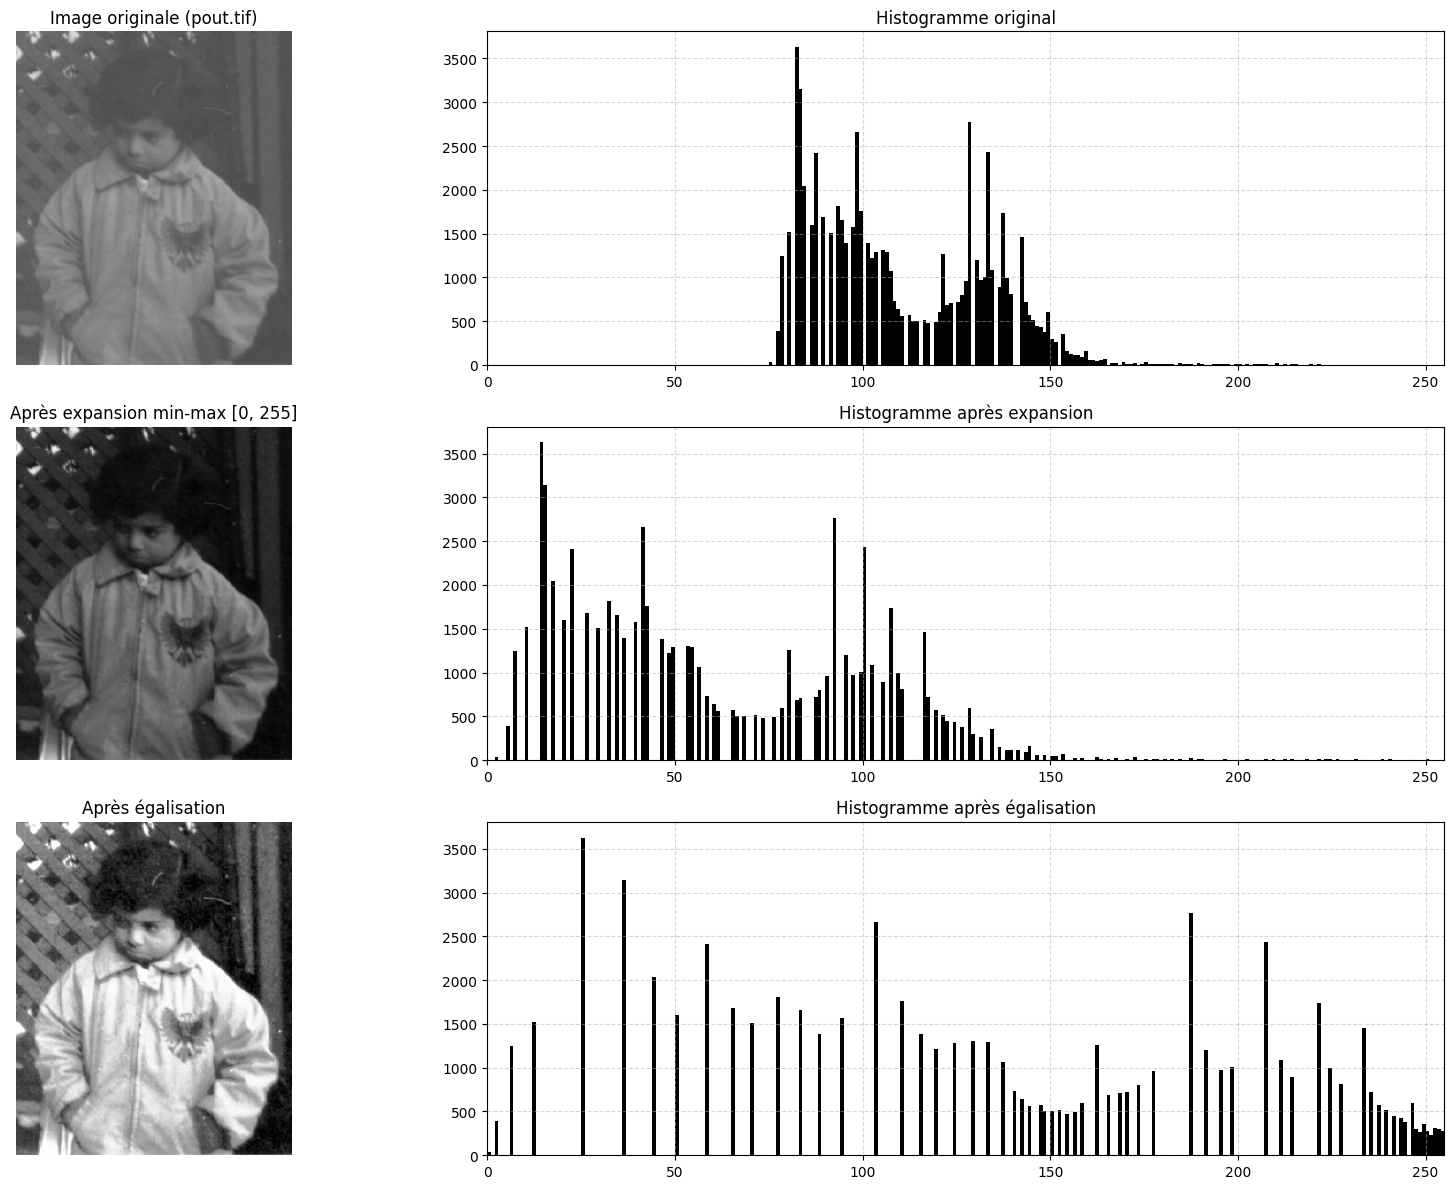

In [ ]:
#Affichage des images et des histogrammes ---
plt.figure(figsize=(18, 12))

# Image originale
plt.subplot(3, 2, 1)
plt.imshow(pout, cmap='gray', vmin=0, vmax=255)
plt.title("Image originale (pout.tif)")
plt.axis('off')

# Histogramme original
plt.subplot(3, 2, 2)
plt.hist(pout.ravel(), bins=256, range=(0, 256), color='black')
plt.title("Histogramme original")
plt.xlim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)

# Image étirée (Expansion min-max)
plt.subplot(3, 2, 3)
plt.imshow(I_exp, cmap='gray', vmin=0, vmax=255) #ehcelle de gris commune : vmin=0, vmax=255
plt.title("Après expansion min-max [0, 255]")
plt.axis('off')

# Histogramme étiré
plt.subplot(3, 2, 4)
plt.hist(I_exp.ravel(), bins=256, range=(0, 256), color='black')
plt.title("Histogramme après expansion")
plt.xlim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)

# Image égalisée
plt.subplot(3, 2, 5)
plt.imshow(pout_eq, cmap='gray', vmin=0, vmax=255)
plt.title("Après égalisation")
plt.axis('off')

# Histogramme étiré
plt.subplot(3, 2, 6)
plt.hist(pout_eq.ravel(), bins=256, range=(0, 256), color='black')
plt.title("Histogramme après égalisation")
plt.xlim([0, 255])
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

7. Calculer μ, C et D pour les trois images.

In [ ]:
# Calcul et comparaison de μ, C et D
# Originale
mu_orig = np.mean(pout_float)
D_orig = I_max - I_min
C_orig = D_orig / 255.0

# Après expansion (sur les valeurs réelles I_exp_float avant arrondi)
I_exp_min = I_exp_float.min()
I_exp_max = I_exp_float.max()

mu_exp = np.mean(I_exp_float)
D_exp = I_exp_max - I_exp_min
C_exp = D_exp / 255.0

#Après égalisation
I_eg_min = pout_eq.min()
I_eg_max = pout_eq.max()

mu_eg = np.mean(pout_eq)
D_eg = I_eg_max - I_eg_min
C_eg = D_eg / 255.0

print(f"--- COMPARAISE DES INDICATEURS ---")
print(f"Originale -> μ: {mu_orig:.2f} | D: {D_orig:.0f} | C: {C_orig:.4f}")
print(f"Expansée  -> μ: {mu_exp:.2f} | D: {D_exp:.0f} | C: {C_exp:.4f}")
print(f"Egalisée  -> μ: {mu_eg:.2f} | D: {D_eg:.0f} | C: {C_eg:.4f}")

--- COMPARAISE DES INDICATEURS ---
Originale -> μ: 110.30 | D: 255 | C: 1.0000
Expansée  -> μ: 61.72 | D: 255 | C: 1.0000
Egalisée  -> μ: 130.38 | D: 255 | C: 1.0000
